## **Projeto de Aprendizado Profundo**


---

## 1 · Descrição do problema – *Image to Text*

O *Image to Text* (captionamento automático) consiste em gerar, para cada imagem, uma legenda em linguagem natural que descreva fielmente seu conteúdo visual.

---

## 2 · Importância

1. **Acessibilidade:** descrições automáticas facilitam a navegação de usuários cegos ou com baixa visão.
2. **Indexação:** legendas de qualidade enriquecem metadados, impactando positivamente o ranqueamento em mecanismos de busca.
3. **Busca multimodal e recomendação:** integrar texto e imagem aprimora sistemas de recuperação de informação.


---

## 3 · Conjunto de dados escolhido – **Flickr30k**

O Flickr30k reúne **≈ 31 000 imagens**, cada uma com **5 legendas** produzidas por anotadores humanos, sendo referência para treinar e avaliar modelos de captionamento.

---


## 4 · Otimizador

Neste projeto, utilizamos o **Adam (Adaptive Moment Estimation)** como otimizador. O Adam é um método de otimização que ajusta dinamicamente a taxa de aprendizagem de cada parâmetro, combinando as vantagens do AdaGrad e do RMSProp.  
- **Taxa de aprendizagem (learning rate):** 1 × 10⁻⁴  
- **Uso no projeto:** aplicado tanto ao encoder (CNN) quanto ao decoder (RNN com Attention) para atualizar os pesos a cada iteração, minimizando a perda de entropia cruzada entre as legendas geradas e as legendas de referência.
---

## 5. Rede Implementada

A arquitetura segue o padrão *encoder–decoder*:

- **EncoderCNN**  
  - Base: ResNet-50 pré-treinada (todas as camadas convolucionais até a penúltima)  
  - Kernel conv1: 7×7, stride 2; MaxPool 3×3, stride 2  
  - Blocos residuais: combinações de convoluções 1×1 e 3×3  
  - AdaptiveAvgPool para saída de dimensão fixa (14×14)  
 
- **DecoderRNN**  
  - Embedding de dimensão 256  
  - LSTMCell com dimensão oculta 512  
  - Dropout(p=0.5) após embedding  
  - Camada final (fully-connected)  

---

## 6. Attention  
  - Soma → ReLU → Linear → Softmax para obter pesos α  
  - Gating via f_β (sigmoid) para controlar influência visual 

## 7. Diagrama da Rede

<div style="text-align: center">''

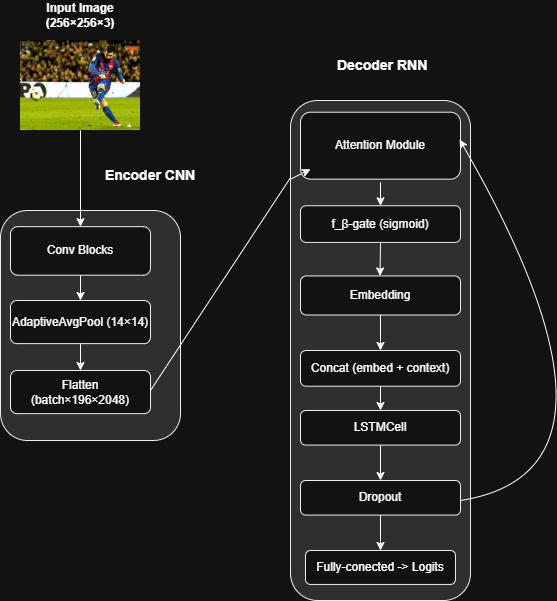

<p><em>Rede implementada para a tarefa Image to Text</em></p>

</div>

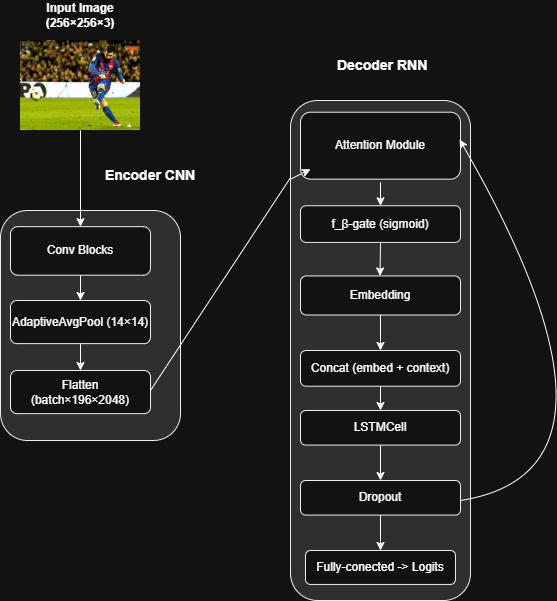

---

## Pré‑requisitos e importações



In [2]:
import os
import nltk
import string
import torch
import torch.utils.data as data
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from PIL import Image
from collections import Counter
from torchvision import transforms
import torchvision.models as models
from tqdm import tqdm
from datasets import load_dataset
import matplotlib.pyplot as plt
import torchvision.transforms as T
from torchinfo import summary
import torch.nn as nn
import torch.nn.functional as F
import textwrap
from PIL import Image

import io


## WordNet (NLTK)

O **WordNet** é um banco de dados lexical muito utilizado no processamento de linguagem natural (PLN). Ele agrupa palavras do inglês em conjuntos de sinônimos chamados *synsets*, conectados por relações semânticas como hiperonímia (relações do tipo “é um”), meronímia (relações do tipo “parte de”) e antônimos.  

No NLTK, o WordNet permite:  

- consultar significados e definições de palavras (glossários);  
- explorar redes semânticas para tarefas como expansão de consulta, similaridade semântica e desambiguação de sentido;  
- obter exemplos de uso, relações hierárquicas e relações de parte-todo.  

Para modelos de legendas automáticas, recursos do WordNet podem ser usados, por exemplo, para enriquecer embeddings, expandir vocabulários ou analisar a coerência semântica das palavras previstas.


In [6]:
import nltk
try:
    nltk.data.find('corpora/wordnet')
except:
    print("Baixando o recurso 'wordnet' do NLTK...")
    nltk.download('wordnet')
    print("Download concluído.")

Baixando o recurso 'wordnet' do NLTK...
Download concluído.


[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## Definição do dispositivo

Verifica se há GPU (CUDA) disponível e define `device` como `"cuda"` ou `"cpu"`.  


In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

## Carregamento do dataset Flickr30k 

Utilizamos o `load_dataset` da Hugging Face para baixar o dataset **nlphuji/flickr30k**, composto por aproximadamente **31 000 imagens**, cada uma associada a **5 legendas humanas**, totalizando cerca de **155 000 pares imagem‑legenda**.
### Características principais:

- **Imagens do Flickr**: capturam pessoas em atividades cotidianas e representam grande variedade de cenários, como interações sociais, esportes e ambiente externo :contentReference.
- **Legendas múltiplas por imagem**: as 5 legendas por imagem permitem análise quantitativa (via métricas BLEU/ROUGE).



In [8]:
ds_dic = load_dataset("nlphuji/flickr30k")

README.md:   0%|          | 0.00/641 [00:00<?, ?B/s]

flickr30k.py: 0.00B [00:00, ?B/s]

0000.parquet:   0%|          | 0.00/506M [00:00<?, ?B/s]

0001.parquet:   0%|          | 0.00/502M [00:00<?, ?B/s]

0002.parquet:   0%|          | 0.00/506M [00:00<?, ?B/s]

0003.parquet:   0%|          | 0.00/512M [00:00<?, ?B/s]

... (2 outputs left out)

0006.parquet:   0%|          | 0.00/495M [00:00<?, ?B/s]

0007.parquet:   0%|          | 0.00/497M [00:00<?, ?B/s]

0008.parquet:   0%|          | 0.00/289M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/31014 [00:00<?, ? examples/s]

## Filtragem dos splits do Flickr30k

Selecionamos os conjuntos de **treino**, **validação** e **teste** usando os filtros disponíveis no dataset carregado e exibimos o resumo de cada um. 

In [9]:
ds = ds_dic['test']
train_dataset = ds.filter(lambda example: example['split'] == 'train')
val_dataset = ds.filter(lambda example: example['split'] == 'val')
test_dataset = ds.filter(lambda example: example['split'] == 'test')
print(train_dataset)
print(val_dataset)
print(test_dataset)


Filter:   0%|          | 0/31014 [00:00<?, ? examples/s]

Filter:   0%|          | 0/31014 [00:00<?, ? examples/s]

Filter:   0%|          | 0/31014 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'caption', 'sentids', 'split', 'img_id', 'filename'],
    num_rows: 29000
})
Dataset({
    features: ['image', 'caption', 'sentids', 'split', 'img_id', 'filename'],
    num_rows: 1014
})
Dataset({
    features: ['image', 'caption', 'sentids', 'split', 'img_id', 'filename'],
    num_rows: 1000
})


Baixa o recurso para tokenização de sentenças.

In [10]:
import nltk
nltk.download('punkt')


[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

## Construção do vocabulário

Esta célula define a classe `Vocabulary`, responsável por gerar o vocabulário do projeto a partir das legendas do dataset. Ela inclui:  
- tokenização de textos (usando `nltk.word_tokenize`),  
- criação de um dicionário de palavras para índices e vice-versa,  
- definição de tokens especiais (`<pad>`, `<start>`, `<end>`, `<unk>`),  
- filtragem mínima de frequência,  
- método para transformar sentenças em sequências de índices (*numericalize*).



In [11]:
from collections import Counter
from nltk.tokenize import word_tokenize

class Vocabulary:
    def __init__(self, freq_threshold=4):
        self.freq_threshold = freq_threshold

        self.itos = {0: "<pad>", 1: "<start>", 2: "<end>", 3: "<unk>"}  # index to string
        self.stoi = {v: k for k, v in self.itos.items()}                # string to index

    def __len__(self):
        return len(self.itos)

    @staticmethod
    def tokenizer(text):
        return word_tokenize(text.lower())

    def build_vocabulary(self, dataset):
        frequencies = Counter()
        idx = 4  # Start indexing after special tokens

        for sample in dataset:

            captions_list = sample['caption']
            if not isinstance(captions_list, list):
                captions_list = [captions_list]

            # Iteramos sobre CADA legenda na lista de legendas da amostra
            for caption in captions_list:
                tokens = self.tokenizer(caption)
                frequencies.update(tokens)

        for word, freq in frequencies.items():
            if freq >= self.freq_threshold:
                self.stoi[word] = idx
                self.itos[idx] = word
                idx += 1

    def numericalize(self, text):
        tokenized_text = self.tokenizer(text)

        return [
            self.stoi.get(token, self.stoi["<unk>"])
            for token in tokenized_text
        ]


In [12]:
vocab = Vocabulary(freq_threshold=3)
vocab.build_vocabulary(train_dataset)

print(f"Vocabulary size: {len(vocab)}")

# Test tokenization and numericalization
caption = "A man is riding a bike on the street."
tokens = vocab.tokenizer(caption)
numericalized = vocab.numericalize(caption)

print("Tokens:", tokens)
print("Indices:", numericalized)

Vocabulary size: 9714
Tokens: ['a', 'man', 'is', 'riding', 'a', 'bike', 'on', 'the', 'street', '.']
Indices: [33, 34, 71, 514, 33, 519, 54, 18, 151, 20]


## Dataset de treino achatado

Define o `ImageCaptionDatasetTrain`, que organiza cada par (imagem, legenda) como um item individual, aproveitando todas as 5 legendas disponíveis por imagem. Também implementa o tokenização, truncamento, e preenchimento (padding) para garantir sequências de comprimento fixo no treinamento.


In [13]:
class ImageCaptionDatasetTrain(data.Dataset):
    """
    Dataset para TREINO.
    "Achata" o dataset para que cada par (imagem, legenda) seja um item individual.
    """
    def __init__(self, dataset, vocab, transform, max_length=50):
        self.vocab = vocab
        self.transform = transform
        self.max_length = max_length
        self.samples = []

        print("Achatando o dataset para o treinamento (usando todas as 5 legendas por imagem)...")
        for sample in tqdm(dataset, desc="Processando amostras"):
            image_info = sample['image']
            # Para cada uma das 5 legendas, criamos um novo item de dados
            for caption_text in sample['caption']:
                self.samples.append({'image': image_info, 'caption': caption_text})

    def __len__(self):
        # O comprimento do dataset agora é ~5x o número de imagens
        return len(self.samples)

    def __getitem__(self, idx):
        sample = self.samples[idx]

        image = sample['image']
        if not isinstance(image, Image.Image):
            image = Image.open(image).convert("RGB")
        image = self.transform(image)

        caption = sample['caption']
        tokens = self.vocab.tokenizer(caption)

        if len(tokens) > (self.max_length - 2):
            tokens = tokens[:self.max_length - 2]
        
        caption_ids = [self.vocab.stoi["<start>"]]
        caption_ids += [self.vocab.stoi.get(token, self.vocab.stoi["<unk>"]) for token in tokens]
        caption_ids.append(self.vocab.stoi["<end>"])
        
        padding_needed = self.max_length - len(caption_ids)
        if padding_needed > 0:
            caption_ids += [self.vocab.stoi["<pad>"]] * padding_needed
            
        return {'image': image, 'caption': torch.tensor(caption_ids)}

## Dataset de validação e teste

Define o `ImageCaptionDatasetVal`, que mantém a lista completa de todas as 5 legendas de referência por imagem, permitindo avaliação mais precisa em métricas de geração de texto.

In [14]:
class ImageCaptionDatasetVal(data.Dataset):
    """
    Dataset para VALIDAÇÃO/TESTE.
    Fornece todas as legendas de referência para uma avaliação precisa com métricas.
    """
    def __init__(self, dataset, transform):
        self.dataset = list(dataset)
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]

        image = sample['image']
        if not isinstance(image, Image.Image):
            image = Image.open(image).convert("RGB")
        image = self.transform(image)
        
        # Retorna a imagem e a LISTA de todas as 5 legendas de referência
        return {'image': image, 'captions_list': sample['caption']}

In [15]:
from torchvision import transforms

image_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


## Collate function para validação

Define a função de agrupamento (*collate*) para o conjunto de validação, empilhando as imagens em um tensor e mantendo as legendas como listas de referência.

In [16]:
def collate_fn_val(batch):
    images = []
    captions_lists = []
    
    for sample in batch:
        images.append(sample['image'])
        captions_lists.append(sample['captions_list'])
        
    # Empilha as imagens num único tensor
    images = torch.stack(images, 0)
    
    return {'image': images, 'captions_list': captions_lists}

In [17]:
print("\nInstanciando os datasets com as novas classes...")
train_data = ImageCaptionDatasetTrain(train_dataset, vocab, image_transform)
val_data = ImageCaptionDatasetVal(val_dataset, image_transform)
test_data = ImageCaptionDatasetVal(test_dataset, image_transform) # Teste usa a mesma estrutura da validação

BATCH_SIZE = 32
train_loader = data.DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
val_loader = data.DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn_val)
test_loader = data.DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn_val)



Instanciando os datasets com as novas classes...
Achatando o dataset para o treinamento (usando todas as 5 legendas por imagem)...


Processando amostras: 100%|██████████| 29000/29000 [01:35<00:00, 302.97it/s]


## Encoder CNN

A classe `EncoderCNN` reaproveita a arquitetura ResNet-50 pré-treinada para extrair mapas de características (features) de alta qualidade a partir das imagens. Para isso:

- **Tronco ResNet-50**: utiliza todos os blocos convolucionais, removendo as camadas de classificação finais (camadas *fully connected* e *avgpool*), mantendo apenas as camadas que aprendem representações visuais profundas.
  
- **Adaptive Pooling**: adapta dinamicamente a resolução espacial de saída para um tamanho fixo (14 × 14), garantindo compatibilidade para o mecanismo de atenção subsequente.

- **Permutação e reshaping**: reorganiza o tensor para o formato `(batch_size, num_pixels, feature_dim)` adequado ao decoder com atenção.

- **Fine-tuning**: congela inicialmente todos os parâmetros da ResNet, mas possibilita destravar gradualmente os blocos finais a partir do layer 5 para refinar a adaptação ao domínio do captioning.

Esse módulo permite transformar cada imagem de entrada em uma grade de vetores de características, que servirá como entrada rica para o decoder gerar legendas.


In [18]:
class EncoderCNN(nn.Module):
    def __init__(self, encoded_image_size=14):
        super(EncoderCNN, self).__init__()
        resnet = models.resnet50(pretrained=True)
        modules = list(resnet.children())[:-2]
        self.resnet = nn.Sequential(*modules)
        self.adaptive_pool = nn.AdaptiveAvgPool2d((encoded_image_size, encoded_image_size))
        self.fine_tune()

    def forward(self, images):
        features = self.resnet(images)
        features = self.adaptive_pool(features)
        features = features.permute(0, 2, 3, 1)
        features = features.view(features.size(0), -1, features.size(-1))
        return features

    def fine_tune(self, fine_tune=True):
        for p in self.resnet.parameters():
            p.requires_grad = False
        for c in list(self.resnet.children())[5:]:
            for p in c.parameters():
                p.requires_grad = fine_tune


## Mecanismo de Atenção

A classe `Attention` implementa o módulo de atenção aditiva, responsável por selecionar dinamicamente quais regiões visuais do mapa de características devem ser enfatizadas em cada passo da geração da legenda. O funcionamento pode ser detalhado assim:

- **Projeções lineares**: transforma as representações do encoder (`encoder_out`) e o estado oculto atual do decoder (`decoder_hidden`) para o mesmo espaço dimensional de atenção.
  
- **Combinação não linear**: soma essas projeções, aplica uma ativação ReLU e passa por mais uma camada linear para obter uma pontuação de atenção para cada posição espacial do encoder.
  
- **Normalização**: usa softmax para transformar as pontuações em pesos (alfa), que indicam a relevância de cada região da imagem.
  
- **Pesagem**: calcula a codificação ponderada (vetor de contexto visual) ao combinar o mapa de características do encoder com os pesos de atenção.

Dessa forma, o decoder pode se concentrar seletivamente em partes relevantes da imagem a cada palavra gerada.

In [19]:
class Attention(nn.Module):
    def __init__(self, encoder_dim, decoder_dim, attention_dim):
        super(Attention, self).__init__()
        self.encoder_att = nn.Linear(encoder_dim, attention_dim)
        self.decoder_att = nn.Linear(decoder_dim, attention_dim)
        self.full_att = nn.Linear(attention_dim, 1)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)

    def forward(self, encoder_out, decoder_hidden):
        att1 = self.encoder_att(encoder_out)
        att2 = self.decoder_att(decoder_hidden).unsqueeze(1)
        att = self.full_att(self.relu(att1 + att2)).squeeze(2)
        alpha = self.softmax(att)
        attention_weighted_encoding = (encoder_out * alpha.unsqueeze(2)).sum(dim=1)
        return attention_weighted_encoding, alpha


## Decoder RNN

A classe `DecoderRNN` implementa a parte geradora da legenda, seguindo o paradigma *encoder-decoder* com atenção. Ela funciona assim:

- **Embedding**: transforma índices de palavras em vetores densos de dimensão fixa.
- **Atenção**: a cada passo, combina o contexto visual mais relevante (calculado pela atenção) com a palavra anterior para decidir qual palavra gerar.
- **LSTMCell**: processa a sequência, mantendo dependências temporais para capturar coerência linguística.
- **Porta f_beta**: controla a quantidade de informação visual a ser usada em cada passo (mecanismo de gating).
- **Camada totalmente conectada**: projeta o vetor de saída do LSTM para o espaço do vocabulário, gerando probabilidades de cada palavra.
- **sample**: método específico de amostragem, que permite gerar legendas palavra a palavra no modo de inferência.

Essa estrutura possibilita ao modelo gerar legendas coerentes, adaptando-se dinamicamente às regiões mais relevantes da imagem a cada palavra prevista.


In [20]:
class DecoderRNN(nn.Module):
    def __init__(self, attention_dim, embed_dim, decoder_dim, vocab_size, encoder_dim=2048, dropout=0.5):
        super(DecoderRNN, self).__init__()
        self.encoder_dim = encoder_dim
        self.decoder_dim = decoder_dim
        self.embed_dim = embed_dim
        self.vocab_size = vocab_size
        self.attention_dim = attention_dim

        self.attention = Attention(encoder_dim, decoder_dim, attention_dim)

        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.dropout = nn.Dropout(dropout)
        self.decode_step = nn.LSTMCell(embed_dim + encoder_dim, decoder_dim)
        self.init_h = nn.Linear(encoder_dim, decoder_dim)
        self.init_c = nn.Linear(encoder_dim, decoder_dim)
        self.f_beta = nn.Linear(decoder_dim, encoder_dim)
        self.sigmoid = nn.Sigmoid()
        self.fc = nn.Linear(decoder_dim, vocab_size)

    def forward(self, encoder_out, captions):
        batch_size = encoder_out.size(0)
        num_pixels = encoder_out.size(1)

        embeddings = self.embedding(captions)

        h, c = self.init_hidden_state(encoder_out)

        decode_lengths = [captions.size(1)] * batch_size
        predictions = torch.zeros(batch_size, captions.size(1), self.vocab_size).to(encoder_out.device)

        for t in range(captions.size(1)):
            attention_weighted_encoding, _ = self.attention(encoder_out, h)

            gate = self.sigmoid(self.f_beta(h))
            attention_weighted_encoding = gate * attention_weighted_encoding

            h, c = self.decode_step(
                torch.cat([embeddings[:, t, :], attention_weighted_encoding], dim=1),
                (h, c)
            )

            preds = self.fc(self.dropout(h))
            predictions[:, t, :] = preds

        return predictions

    def init_hidden_state(self, encoder_out):
        mean_encoder_out = encoder_out.mean(dim=1)
        h = self.init_h(mean_encoder_out)
        c = self.init_c(mean_encoder_out)
        return h, c

    def sample(self, encoder_out, vocab, idx2word, device, max_len=20):
        """
        Generate caption from encoder output.

        Args:
            encoder_out: Output from encoder, shape (1, num_pixels, encoder_dim)
            vocab: word-to-index dictionary
            idx2word: index-to-word dictionary
            device: 'cuda' or 'cpu'
            max_len: maximum length of caption

        Returns:
            caption: list of words (without <start> and <end>)
        """
        assert encoder_out.size(0) == 1, "Batch size must be 1 for sampling."

        h, c = self.init_hidden_state(encoder_out)

        #input_word = torch.tensor([vocab['<start>']]).to(device)  # (1,)
        input_word = torch.tensor([vocab.stoi['<start>']]).to(device)  # (1,)
        
        embeddings = self.embedding(input_word)  # (1, embed_dim)

        caption = []

        for _ in range(max_len):
            attention_weighted_encoding, _ = self.attention(encoder_out, h)

            gate = self.sigmoid(self.f_beta(h))
            attention_weighted_encoding = gate * attention_weighted_encoding

            h, c = self.decode_step(
                torch.cat([embeddings, attention_weighted_encoding], dim=1),
                (h, c)
            )

            preds = self.fc(h)  # (1, vocab_size)
            predicted_id = preds.argmax(1)  # (1,)

            word = idx2word[predicted_id.item()]

            if word == '<end>':
                break

            caption.append(word)

            embeddings = self.embedding(predicted_id)

        return caption



## Configuração do treinamento

Define a função de perda (`CrossEntropyLoss` ignorando o token `<pad>`), instancia o encoder e o decoder no dispositivo escolhido, e inicializa o otimizador Adam com taxa de aprendizado de 1e-4.  
Também importa métricas de avaliação de texto, como BLEU e ROUGE, para análise futura da qualidade das legendas geradas.


In [21]:
from torchmetrics.text import BLEUScore, ROUGEScore

# A definição do criterion, encoder, decoder e optimizer permanece a mesma
criterion = nn.CrossEntropyLoss(ignore_index=vocab.stoi['<pad>'])
encoder = EncoderCNN().to(device)
decoder = DecoderRNN(attention_dim=512, embed_dim=256, decoder_dim=512, vocab_size=len(vocab)).to(device)
params = list(decoder.parameters()) + list(encoder.parameters())
optimizer = torch.optim.Adam(params, lr=1e-4)


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 175MB/s] 


## Sumário da Rede

Nesta célula, apresentamos o sumário das arquiteturas do `EncoderCNN` e do `DecoderRNN` utilizando a função `summary` do `torchinfo`. Esse sumário detalha as camadas, tamanhos de entrada e saída e a quantidade de parâmetros treináveis de cada componente da rede.

- **EncoderCNN**  
  O sumário do encoder considera imagens de entrada com tamanho `(3, 256, 256)` (canal RGB, altura e largura 256) em batch size 1.

- **DecoderRNN**  
  O sumário do decoder considera como entrada a saída do encoder transformada em uma sequência de vetores de dimensão `(196, 2048)` (correspondente a um grid 14×14 de características extraídas) e uma sequência de palavras de comprimento máximo 50.

In [ ]:
from torchinfo import summary

print(">>> Sumário do EncoderCNN:")
summary(
    encoder,
    input_size=(1, 3, 256, 256),
    col_names=("input_size", "output_size", "num_params"),
    depth=3
)

>>> Sumário do EncoderCNN:


Layer (type:depth-idx)                        Input Shape               Output Shape              Param #
EncoderCNN                                    [1, 3, 256, 256]          [1, 196, 2048]            --
├─Sequential: 1-1                             [1, 3, 256, 256]          [1, 2048, 8, 8]           --
│    └─Conv2d: 2-1                            [1, 3, 256, 256]          [1, 64, 128, 128]         (9,408)
│    └─BatchNorm2d: 2-2                       [1, 64, 128, 128]         [1, 64, 128, 128]         (128)
│    └─ReLU: 2-3                              [1, 64, 128, 128]         [1, 64, 128, 128]         --
│    └─MaxPool2d: 2-4                         [1, 64, 128, 128]         [1, 64, 64, 64]           --
│    └─Sequential: 2-5                        [1, 64, 64, 64]           [1, 256, 64, 64]          --
│    │    └─Bottleneck: 3-1                   [1, 64, 64, 64]           [1, 256, 64, 64]          (75,008)
│    │    └─Bottleneck: 3-2                   [1, 256, 64, 64]          

In [25]:
print("\n>>> Sumário do DecoderRNN:")
# Crie tensores dummy com as dimensões corretas
encoder_input_dummy = torch.randn(1, 196, 2048).to(device)  # (batch_size, num_pixels, encoder_dim)
captions_dummy = torch.randint(0, len(vocab), (1, 50)).to(device) # (batch_size, seq_length)

summary(
    decoder,
    input_data=[encoder_input_dummy, captions_dummy],
    col_names=("input_size", "output_size", "num_params"),
    depth=3
)


>>> Sumário do DecoderRNN:


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
DecoderRNN                               [1, 196, 2048]            [1, 50, 9714]             --
├─Embedding: 1-1                         [1, 50]                   [1, 50, 256]              2,486,784
├─Linear: 1-2                            [1, 2048]                 [1, 512]                  1,049,088
├─Linear: 1-3                            [1, 2048]                 [1, 512]                  1,049,088
├─Attention: 1-4                         [1, 196, 2048]            [1, 2048]                 --
│    └─Linear: 2-1                       [1, 196, 2048]            [1, 196, 512]             1,049,088
│    └─Linear: 2-2                       [1, 512]                  [1, 512]                  262,656
│    └─ReLU: 2-3                         [1, 196, 512]             [1, 196, 512]             --
│    └─Linear: 2-4                       [1, 196, 512]             [1, 196, 1]               513
│

Observação: A etiqueta `(recursive)` no sumário do decoder aparece porque, sendo uma Rede Neural Recorrente (RNN), o decoder reutiliza as mesmas camadas (`LSTMCell`, `Attention`, etc.) em um laço para processar cada palavra da sequência. A ferramenta `torchinfo` identifica essa reutilização e conta os parâmetros de cada camada apenas uma vez para evitar uma contagem inflacionada.

## Métricas de avaliação: BLEU e ROUGE-L

- **BLEU (Bilingual Evaluation Understudy)**: avalia a precisão n-gram (unigram, bigram, trigram etc.) das legendas geradas em relação às referências humanas, medindo a sobreposição de palavras e a fluência sintática. É muito usado em tradução automática e captioning para verificar se as palavras previstas aparecem na sequência correta.

- **ROUGE-L**: mede a similaridade entre a sequência gerada e as de referência, priorizando o maior subconjunto ordenado de palavras em comum (LCS — longest common subsequence). ROUGE-L captura aspectos de coerência global, pois não se limita a pequenas janelas n-gram, sendo útil para avaliar a qualidade de resumos ou legendas completas.

Essas métricas complementam-se, fornecendo uma visão quantitativa de quão próxima a legenda gerada está de uma legenda humana.


In [22]:
def validate_with_metrics(encoder, decoder, val_loader, device, vocab):
    encoder.eval()
    decoder.eval()

    # Inicializa as métricas
    bleu_metric = BLEUScore()
    rouge_metric = ROUGEScore()
    
    with torch.no_grad():
        progress_bar = tqdm(val_loader, total=len(val_loader), desc="Validação com Métricas")
        for batch in progress_bar:
            images = batch['image'].to(device)
            # Lista de listas de strings (batch_size, 5 legendas)
            reference_captions = batch['captions_list'] 
            
            # Gera as legendas previstas (1 por imagem no lote)
            predicted_captions = []
            for image in images:
                # Usa o método .sample() que já existe no seu decoder
                generated_list = decoder.sample(encoder(image.unsqueeze(0)), vocab, vocab.itos, device)
                predicted_captions.append(' '.join(generated_list))
            
            # Atualiza as métricas. O formato dos dados já é o correto.
            bleu_metric.update(predicted_captions, reference_captions)
            rouge_metric.update(predicted_captions, reference_captions)

    # Calcula o resultado final de todas as métricas
    val_metrics = {
        'BLEU': bleu_metric.compute().item(),
        'ROUGE-L': rouge_metric.compute()['rougeL_fmeasure'].item()
    }
    
    # Com a nova estrutura, não calculamos mais a perda (loss) na validação,
    # pois não há um alvo único. O foco são as métricas.
    avg_val_loss = 0.0

    encoder.train()
    decoder.train()

    return avg_val_loss, val_metrics

## Laço de treino e validação

Define a função `train_and_evaluate`, que organiza o treinamento por épocas, monitorando a perda de treino e calculando métricas de validação (BLEU e ROUGE-L) ao final de cada época.  

In [23]:
def train_and_evaluate(encoder, decoder, train_loader, val_loader, criterion, optimizer, vocab, device, num_epochs=10, save_path="checkpoint.pth"):
    history = {'train_loss': [], 'val_loss': [], 'bleu': [], 'rouge': []}

    for epoch in range(num_epochs):
        # Treino
        encoder.train()
        decoder.train()
        total_train_loss = 0.0
        progress_bar = tqdm(train_loader, desc=f"Época {epoch+1}/{num_epochs} [Treino]")
        for batch in progress_bar:
            images = batch['image'].to(device)
            captions = batch['caption'].to(device)
            
            optimizer.zero_grad()
            encoder_out = encoder(images)
            outputs = decoder(encoder_out, captions[:, :-1])
            targets = captions[:, 1:]
            
            loss = criterion(outputs.view(-1, len(vocab)), targets.reshape(-1))
            loss.backward()
            optimizer.step()
            
            total_train_loss += loss.item()
            progress_bar.set_postfix(loss=loss.item())
        
        avg_train_loss = total_train_loss / len(train_loader)
        
        # Validação com métricas
        avg_val_loss, val_metrics = validate_with_metrics(encoder, decoder, val_loader, device, vocab)
        
        # Armazenar resultados no histórico
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss) # Será 0, mas mantemos por consistência
        history['bleu'].append(val_metrics['BLEU'])
        history['rouge'].append(val_metrics['ROUGE-L'])

        # Imprimir o relatório da época
        print(f"\nFIM DA ÉPOCA {epoch + 1}:")
        print(f"  -> Perda de Treino: {avg_train_loss:.4f}")
        print(f"  -> Métricas de Validação: BLEU={val_metrics['BLEU']:.4f}, ROUGE-L={val_metrics['ROUGE-L']:.4f}\n")
        
        # Salvar checkpoint
        torch.save({'encoder_state_dict': encoder.state_dict(), 'decoder_state_dict': decoder.state_dict(), 'vocab': vocab}, save_path)
    
    print("Treinamento concluído!")
    return history

In [24]:
history = train_and_evaluate(
    encoder=encoder,
    decoder=decoder,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    vocab=vocab,
    device=device,
    num_epochs=5
)

Validação com Métricas: 100%|██████████| 32/32 [00:22<00:00,  1.44it/s]



FIM DA ÉPOCA 1:
  -> Perda de Treino: 4.1202
  -> Métricas de Validação: BLEU=0.1000, ROUGE-L=0.3912



Validação com Métricas: 100%|██████████| 32/32 [00:21<00:00,  1.51it/s]



FIM DA ÉPOCA 2:
  -> Perda de Treino: 3.4060
  -> Métricas de Validação: BLEU=0.1319, ROUGE-L=0.4252



Validação com Métricas: 100%|██████████| 32/32 [00:21<00:00,  1.51it/s]



FIM DA ÉPOCA 3:
  -> Perda de Treino: 3.1420
  -> Métricas de Validação: BLEU=0.1465, ROUGE-L=0.4333



Validação com Métricas: 100%|██████████| 32/32 [00:21<00:00,  1.49it/s]



FIM DA ÉPOCA 4:
  -> Perda de Treino: 2.9719
  -> Métricas de Validação: BLEU=0.1529, ROUGE-L=0.4385



Validação com Métricas: 100%|██████████| 32/32 [00:21<00:00,  1.50it/s]



FIM DA ÉPOCA 5:
  -> Perda de Treino: 2.8468
  -> Métricas de Validação: BLEU=0.1535, ROUGE-L=0.4355

Treinamento concluído!


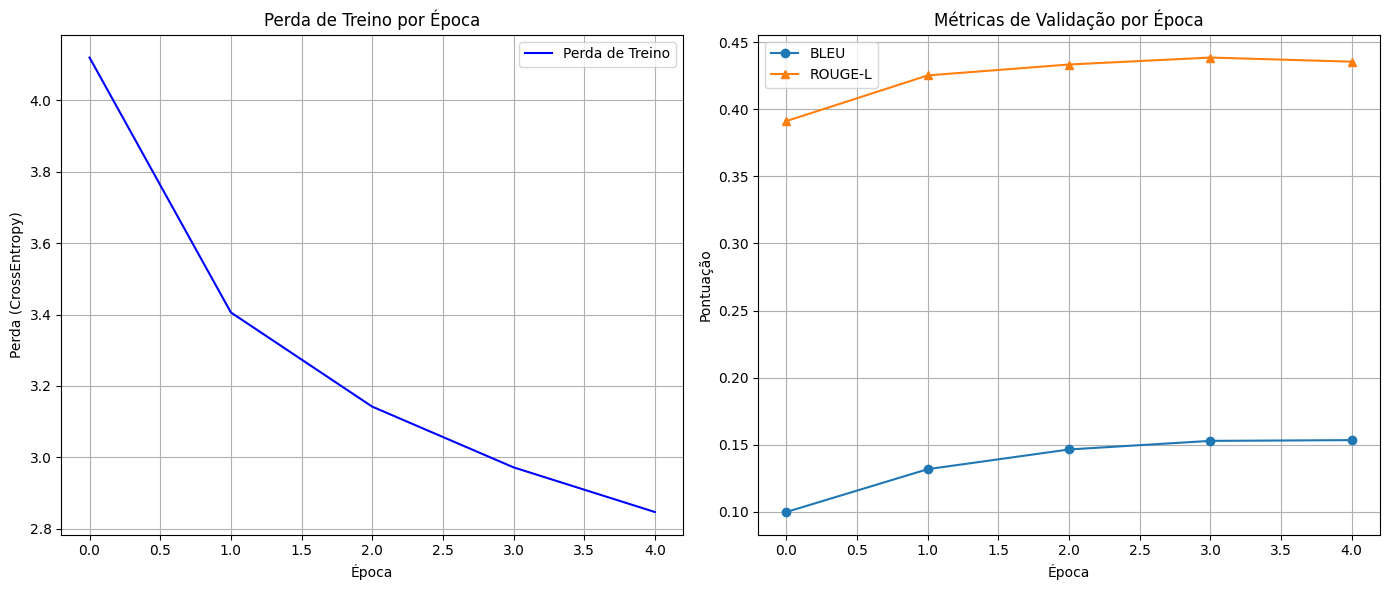

In [25]:
def plot_history(history):
    # Gráfico 1: Perda (Loss) de Treino
    plt.figure(figsize=(14, 6))
    plt.subplot(1, 2, 1)
    plt.plot(history['train_loss'], label='Perda de Treino', color='blue')
    plt.title('Perda de Treino por Época')
    plt.xlabel('Época')
    plt.ylabel('Perda (CrossEntropy)')
    plt.legend()
    plt.grid(True)

    # Gráfico 2: Métricas de Validação
    plt.subplot(1, 2, 2)
    plt.plot(history['bleu'], label='BLEU', marker='o')
    plt.plot(history['rouge'], label='ROUGE-L', marker='^')
    plt.title('Métricas de Validação por Época')
    plt.xlabel('Época')
    plt.ylabel('Pontuação')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()

# Plota o histórico salvo após o treinamento
plot_history(history)

## Geração de legenda para uma imagem

A função `caption_image` executa a geração de uma legenda completa a partir de uma única imagem, utilizando o encoder para extrair as características visuais e o método `.sample()` do decoder para produzir palavra por palavra até atingir o comprimento máximo ou encontrar o token de fim.  
Retorna a legenda final como texto pronto para exibição ou avaliação.


In [26]:
def caption_image(encoder, decoder, image, vocab, device, max_len=30):
    encoder.eval()
    decoder.eval()

    with torch.no_grad():
        # O método .sample() já espera uma imagem com dimensão de lote
        encoder_out = encoder(image.unsqueeze(0).to(device))
        caption_list = decoder.sample(encoder_out, vocab, vocab.itos, device, max_len)

    return ' '.join(caption_list)

## Visualização de resultados

Define funções utilitárias para:  
- **denormalizar** tensores de imagem (retornando-os ao intervalo de cores original após normalização de treinamento),  
- **exibir imagens** junto com a legenda gerada pelo modelo e as legendas de referência humanas, permitindo comparação qualitativa.  


In [27]:
def denormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    tensor = tensor.clone().cpu()
    tensor = tensor * std + mean
    return torch.clamp(tensor, 0, 1)

def show_image_with_captions(image_tensor, generated_caption, reference_captions):
    """
    Exibe a imagem com a legenda gerada como título e as legendas de referência abaixo.
    """
    image = denormalize(image_tensor)
    image = T.ToPILImage()(image)
    
    plt.figure(figsize=(8, 8))
    plt.imshow(image)
    
    # Formata a legenda gerada para quebrar a linha se for muito longa
    wrapped_title = textwrap.fill(f"Gerada: {generated_caption}", width=60)
    plt.title(wrapped_title, fontsize=12)
    
    # Formata e exibe as legendas de referência abaixo da imagem
    refs_text = "Referências Humanas:\n" + "\n".join([f"- {textwrap.fill(ref, width=60)}" for ref in reference_captions])
    plt.xlabel(refs_text, fontsize=10, ha='center', va='top')
    
    plt.axis('off')
    plt.show()


MODELO GEROU: 'a group of people are standing in front of a building .'

LEGENDAS DE REFERÊNCIA (RESPOSTAS CORRETAS):
1: 'A bride in a light pink dress poses for a picture with male relatives and is being photographed by a man in a cream shirt with white pants.'
2: 'A man in light colored clothing photographs a group of men wearing dark suits and hats standing around a woman dressed in a strapless gown.'
3: 'A photographer takes a picture of a group of one girl in a pink dress and 10 boys in suits and hats.'
4: 'A man photographs a woman in a pink dress and a throng of men in suits.'
5: 'Man taking a photograph of a well dressed group of teens.'


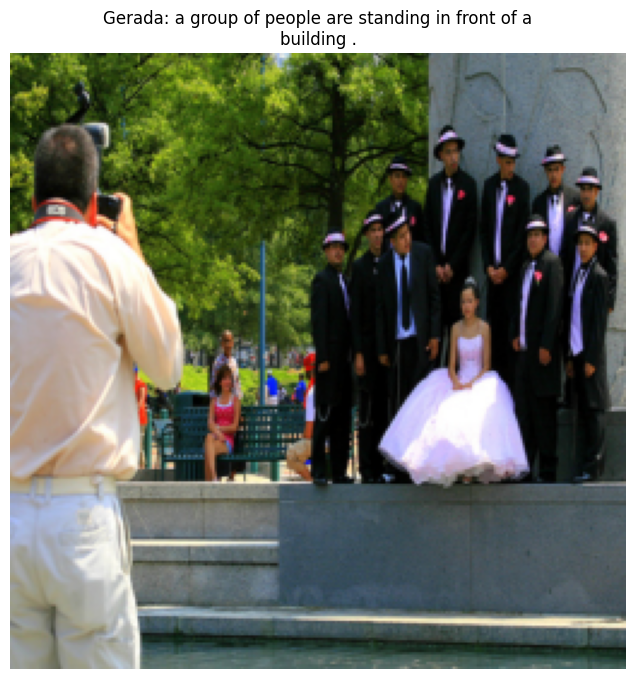

In [28]:
# Pega um único lote do test_loader para visualizar
batch = next(iter(test_loader))

# Escolha um índice da imagem no lote para testar (ex: a primeira imagem)
idx_to_test = 5

image_to_test = batch['image'][idx_to_test]
references = batch['captions_list'][idx_to_test]

# 1. Gera a legenda usando o modelo
predicted_caption = caption_image(encoder, decoder, image_to_test, vocab, device)

# 2. Exibe tudo junto para comparação
print("="*80)
print(f"MODELO GEROU: '{predicted_caption}'")
print("\nLEGENDAS DE REFERÊNCIA (RESPOSTAS CORRETAS):")
for i, ref in enumerate(references):
    print(f"{i+1}: '{ref}'")
print("="*80)

show_image_with_captions(image_to_test, predicted_caption, references)

---

## Testes com imagens

In [ ]:
if True:
    import os
    checkpoint_path = '/kaggle/input/checkpoint_5_epoch/pytorch/default/1/checkpoint.pth'
    
    if os.path.exists(checkpoint_path):
        print(f"Checkpoint encontrado em: {checkpoint_path}")
        print(f"Tamanho do arquivo: {os.path.getsize(checkpoint_path) / (1024*1024):.2f} MB")
    else:
        print("Checkpoint não encontrado.")

Checkpoint encontrado em: /kaggle/input/checkpoint_5_epoch/pytorch/default/1/checkpoint.pth
Tamanho do arquivo: 157.77 MB


## Geração de legenda com Beam Search

A função `generate_caption_beam_search` implementa a estratégia de *beam search* para geração de legendas mais robusta. Diferentemente da geração padrão palavra a palavra (greedy), o beam search mantém **k** sequências candidatas simultaneamente, expandindo em cada passo as continuidades mais promissoras.  

- A cada etapa, o modelo avalia as próximas palavras possíveis e combina seus log-probabilidades com a sequência corrente, criando múltiplos caminhos possíveis.  
- Após expandir todos os candidatos, seleciona-se apenas os **k** melhores para seguir, controlando a diversidade e evitando escolhas precipitadas.  
- Ao fim, as sequências candidatas completas são avaliadas e normalizadas pelo comprimento, retornando a melhor legenda segundo a pontuação acumulada.

Isso garante que a legenda final seja mais estável e fluida do que a gerada apenas pelo algoritmo de amostragem padrão (*greedy*), explorando melhor o espaço de busca de frases possíveis.


In [ ]:
def generate_caption_beam_search(encoder, decoder, image_tensor, vocab, beam_size=5, max_len=40):
    """
    Versão otimizada e corrigida do Beam Search.
    """
    encoder.eval()
    decoder.eval()
    
    device = image_tensor.device
    itos = vocab.itos
    stoi = vocab.stoi
    k = beam_size

    with torch.no_grad():
        encoder_out = encoder(image_tensor.unsqueeze(0))
        h, c = decoder.init_hidden_state(encoder_out)

        # Inicia com o token <start>
        start_token_idx = stoi['<start>']
        
        # Guardará as sequências candidatas: (log_prob, sequencia, hidden, cell)
        k_beams = [(0.0, [start_token_idx], h, c)]
        completed_beams = []

        for _ in range(max_len):
            new_k_beams = []
            
            for log_prob, seq, h, c in k_beams:
                last_word_idx = torch.tensor([seq[-1]]).to(device)
                
                # Se o último token for <end>, finaliza este feixe
                if last_word_idx.item() == stoi['<end>']:
                    completed_beams.append((log_prob, seq))
                    continue

                embeddings = decoder.embedding(last_word_idx)
                attention_weighted_encoding, _ = decoder.attention(encoder_out, h)
                gate = decoder.sigmoid(decoder.f_beta(h))
                attention_weighted_encoding = gate * attention_weighted_encoding
                
                h_next, c_next = decoder.decode_step(
                    torch.cat([embeddings, attention_weighted_encoding], dim=1), (h, c)
                )

                preds = decoder.fc(h_next)
                log_probs = F.log_softmax(preds, dim=1).squeeze(0)

                # Pega as k palavras mais prováveis para continuar este feixe
                top_k_log_probs, top_k_indices = torch.topk(log_probs, k)
                
                # Adiciona os novos candidatos
                for i in range(k):
                    new_seq = seq + [top_k_indices[i].item()]
                    new_log_prob = log_prob + top_k_log_probs[i].item()
                    new_k_beams.append((new_log_prob, new_seq, h_next, c_next))

            # Se todos os feixes terminaram, para
            if not new_k_beams:
                break
                
            # Ordena todos os candidatos e mantém os k melhores
            new_k_beams.sort(key=lambda x: x[0], reverse=True)
            k_beams = new_k_beams[:k]

        # Adiciona os feixes que não terminaram à lista de completos
        completed_beams.extend(k_beams)
        
        # Seleciona o melhor feixe (normalizado pelo comprimento)
        best_beam = sorted(completed_beams, key=lambda x: x[0] / len(x[1]), reverse=True)[0]
        best_seq_indices = best_beam[1]
        
        caption_words = [itos[idx] for idx in best_seq_indices if idx not in {stoi['<start>'], stoi['<end>'], stoi['<pad>']}]
        
    return ' '.join(caption_words)


In [ ]:
def generate_caption_greedy(encoder, decoder, image_tensor, vocab, device, max_len=40):
    return ' '.join(decoder.sample(encoder(image_tensor.unsqueeze(0)), vocab, vocab.itos, device, max_len))

In [ ]:
# Função de visualização
def show_image_with_captions(image_tensor, greedy_caption, beam_caption, reference_captions):
    # Desnormalizar a imagem
    mean = torch.tensor([0.485, 0.456, 0.406], device=image_tensor.device).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=image_tensor.device).view(3, 1, 1)
    image = image_tensor.clone() * std + mean
    image = torch.clamp(image, 0, 1)
    image = transforms.ToPILImage()(image)
    
    plt.figure(figsize=(10, 10))
    plt.imshow(image)
    plt.axis('off')

    title = f"Greedy: {textwrap.fill(greedy_caption, width=80)}\nBeam (k=5): {textwrap.fill(beam_caption, width=80)}"
    plt.title(title, fontsize=12, loc='left')
    
    refs_text = "Referências Humanas:\n" + "\n".join([f"- {textwrap.fill(ref, width=80)}" for ref in reference_captions])
    plt.xlabel(refs_text, fontsize=10, ha='left', va='top')
    plt.show()

A carregar o checkpoint de: /kaggle/input/checkpoint_5_epoch/pytorch/default/1/checkpoint.pth
Modelos e vocabulário carregados com sucesso.
A gerar legendas...

LEGENDA (Greedy Search): 'a group of people are riding bikes on a trail .'
LEGENDA (Beam Search k=5): 'a group of people are riding bikes on a trail .'

EXEMPLO DE LEGENDA VERDADEIRA: 'Six people ride mountain bikes through a jungle environment.'


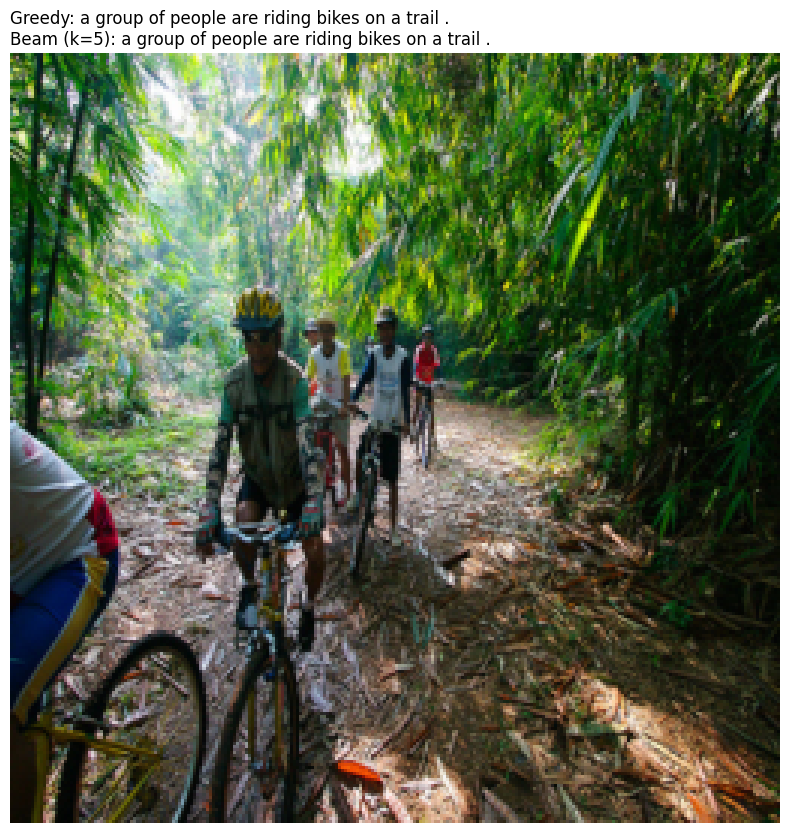

In [ ]:
if True:
    # ==============================================================================
    #  CARREGAMENTO DO CHECKPOINT E MODELOS
    # ==============================================================================

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    checkpoint_path = '/kaggle/input/checkpoint_5_epoch/pytorch/default/1/checkpoint.pth' # Use o checkpoint da Época 5, por exemplo.
    
    print(f"A carregar o checkpoint de: {checkpoint_path}")
    
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    
    vocab = checkpoint['vocab']
    
    # Recria a arquitetura dos modelos
    encoder = EncoderCNN().to(device)
    decoder = DecoderRNN(attention_dim=512, embed_dim=256, decoder_dim=512, vocab_size=len(vocab)).to(device)
    
    # Carrega os pesos salvos
    encoder.load_state_dict(checkpoint['encoder_state_dict'])
    decoder.load_state_dict(checkpoint['decoder_state_dict'])
    
    encoder.eval()
    decoder.eval()
    print("Modelos e vocabulário carregados com sucesso.")
    
    
    # ==============================================================================
    #  BLOCO DE TESTE PRINCIPAL
    # ==============================================================================
    
    # Pega um único lote do test_loader
    test_batch = next(iter(test_loader))
    
    # Escolha um índice da imagem no lote para testar (0 a 31)
    idx_to_test = 30 # Você estava a usar o índice 4, vamos mantê-lo
    
    # --- CORREÇÃO APLICADA AQUI ---
    image_tensor = test_batch['image'][idx_to_test].to(device)
    # Acessa a chave correta 'captions_list' para obter a lista de 5 strings de referência
    reference_captions = test_batch['captions_list'][idx_to_test]
    # Pega a primeira referência apenas para exibição no print (opcional)
    true_caption_example = reference_captions[0]
    
    # Gera legendas usando ambos os métodos
    print("A gerar legendas...")
    greedy_caption = generate_caption_greedy(encoder, decoder, image_tensor, vocab, device)
    beam_caption = generate_caption_beam_search(encoder, decoder, image_tensor, vocab, beam_size=5) # beam_size=5 é um bom valor
    
    # Exibe os resultados para comparação
    print("\n" + "="*80)
    print(f"LEGENDA (Greedy Search): '{greedy_caption}'")
    print(f"LEGENDA (Beam Search k=5): '{beam_caption}'")
    print(f"\nEXEMPLO DE LEGENDA VERDADEIRA: '{true_caption_example}'")
    print("="*80)
    
    # Exibe a imagem com todas as legendas para uma análise visual completa
    show_image_with_captions(image_tensor, greedy_caption, beam_caption, reference_captions)

## Geração de legendas - Imagem Aleatória da Internet

A imagem é pré-processada por meio de redimensionamento e normalização, convertida em tensor e transferida para o dispositivo adequado. O modelo gera duas legendas automáticas, uma via método *greedy* e outra com *beam search* de largura 5.

Modelo carregado com sucesso.

A baixar e a processar a imagem de: https://static01.nyt.com/images/2020/09/25/sports/25soccer-nationalWEB1/merlin_177451008_91c7b66d-3c8a-4963-896e-54280f374b6d-superJumbo.jpg

LEGENDA GERADA: 'two soccer players are playing soccer .'
LEGENDA GERADA BEAM: 'two soccer players are playing soccer .'


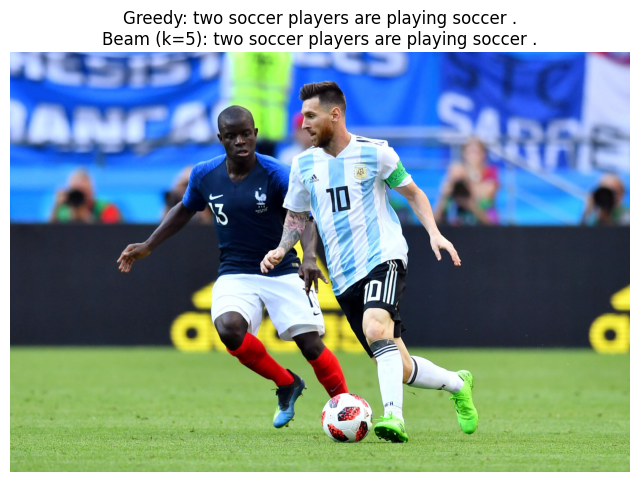

In [ ]:
import torchvision.transforms as transforms
import requests

if True:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    encoder.eval()
    decoder.eval()
    print("Modelo carregado com sucesso.")
    
    image_url = "https://static01.nyt.com/images/2020/09/25/sports/25soccer-nationalWEB1/merlin_177451008_91c7b66d-3c8a-4963-896e-54280f374b6d-superJumbo.jpg"
    
    image_transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])
    
    print(f"\nA baixar e a processar a imagem de: {image_url}")
    try:
        response = requests.get(image_url)
        response.raise_for_status() 
    
        pil_image = Image.open(io.BytesIO(response.content)).convert("RGB")
        image_tensor = image_transform(pil_image).to(device)
    
        greedy_caption = generate_caption_greedy(encoder, decoder, image_tensor, vocab, device)
        beam_caption = generate_caption_beam_search(encoder, decoder, image_tensor, vocab, beam_size=5) # beam_size=5 é um bom valor
    
        print("\n" + "="*80)
        print(f"LEGENDA GERADA: '{greedy_caption}'")
        print(f"LEGENDA GERADA BEAM: '{beam_caption}'")
        print("="*80)
    
        # Exibe a imagem original com a legenda gerada
        plt.figure(figsize=(8, 8))
        plt.imshow(pil_image)
        title = f"Greedy: {textwrap.fill(greedy_caption, width=80)}\nBeam (k=5): {textwrap.fill(beam_caption, width=80)}"
        plt.title(title)
        plt.axis('off')
        plt.show()
    
    except Exception as e:
        print(f"Ocorreu um erro: {e}")

## Conclusão

A partir da realização do trabalho e da observação dos resultados, é possível conlcuir que o projeto de geração de legendas para imagens permitiu que fosse aplicado o conhecimento adquirido durante o curso. Desde a obtenção dos dados e a construção de um vocabulario até o resultado final, obtendo legendas de imagens de maneira satisfatória, o projeto apresentou diversos desafios e fez com que a parte teorica da disciplina pudesse ser colocada em prática.

A arquitetura escolhida, baseada em um encoder de Visão CNN, um decoder de Linguagem RNN com um mecanismo de atenção e o otimizador ADAM, mostrou-se eficaz fazendo o uso do Flickr30k para o treinamento. 

## Principais desafios

#### Limitação de Hardware

Um dos primeiros desafios foi a limitação de hardware. O treinamento da rede foi muito exigente e logo foi perceptivel que o uso do Kaggle seria necessário para executar o codigo. Mesmo com GPU fornecida pelo Kaggle, o treinamento final levou em média 12 horas para ser completado.

#### Pré-processamento de Dados

A preparação do conjunto de dados foi uma etapa mais complexa do que o previsto. Isso envolveu não apenas o redimensionamento e normalização das imagens, mas também a tokenização das legendas, a criação de um vocabulário, o tratamento de palavras raras e o preenchimento (padding) de sequências para formar lotes de dados de tamanho uniforme. 

Além disso, essa etapa teve que ser visitada em outros momentos da elaboração do TP, para que erros que estavam sendo recorrentes fossem solucionados. 
Um exemplo foi o erro relacionado a má geração de legendas, em que foi observamos que o modelo gerava legendas com frequência excessiva do token "unk", resultando em saídas de baixa qualidade como "a man riding a "unk" on a "unk"".
Após uma invetigação, foi notado que o problema acontecia devido a dois principais fatores: 
- O uso de threshold baixo, em que a classe de vocabulário foi inicializada com um limiar de frequência de 3, que descartava qualquer palavra que aparecesse menos de três vezes nos dados de treinamento.
- Subutilização das legendas do Flickr30k, em que o processo de construção do vocabulário utilizava apenas a primeira das cinco legendas disponíveis para cada imagem no dataset, o que tornava muito difícil para palavras relevantes atingirem o limiar de frequência.

#### Utilização das métricas

Inicialmente, a rede apenas gerava as legendas e não havia a coleta de métricas acerca do que estava sendo realizado, deixando duvidas sobre o motivo do mal desempenho do modelo.
Algumas hipoteses foram elaboradas e foi cogitada a substituição do conjunto de dados utilzados para um maior, porém somente com a geração analise correta de métricas junto com as imagens e legendas foi possível entender o que deveria ser feito e para a melhoria do modelo.
Por meio da utilização dessas métricas, como o BLEU e o ROUGE-L,foi possível identificar os pontos ótimos para o treinamento do modelo, evitando o under e o overfit.

## Principais Aprendizados Adquiridos

Para a implementação do trabalho, como mencionado acima, foi utilizada uma arquitetura Encoder-Decoder, envolvendo não apenas instanciar um modelo pré-treinado, mas também dissecar suas camadas para extrair os feature maps de uma CNN (Encoder) e utilizá-los para condicionar o estado oculto de uma RNN (Decoder). Essa etapa do trabalho foi uma das que mais proporcionou aprendizado técnico, assim como a implementação do mecanismo de atenção.

Além disso, o projeto proporcionou o uso de métricas de forma estratégica para guiar o treinamento. A prática de monitorar e plotar as curvas de perda de treino e validação a cada época foi crucial de modo que foi possivel identificar os pontos de overfitting, o momento em que a perda de validação começa a estagnar ou aumentar enquanto a de treino continua a cair. Além da função de perda, foi implementada a avaliação com a métrica BLEU no conjunto de validação ao final de cada época. O "ponto ideal" de treinamento e o modelo final foram escolhidos não apenas com base na menor perda de validação, mas no checkpoint que apresentou o melhor equilíbrio entre a perda e a maior pontuação BLEU, evitando assim o sobreajuste aos dados de treinamento.

E finalmente, a experimentação com diferentes estratégias de decodificação (Greedy Search vs. Beam Search) demonstrou como a fase de inferência é igualmente crítica. A implementação da Beam Search, embora mais complexa, foi um exercício técnico que elevou drasticamente a qualidade e a coerência das legendas finais exibidas.